# Mini-Project 4: Rainfall Pattern & Crop Suitability Analyser

**Scenario.** An agricultural extension officer wants to compare rainfall regimes across regions and advise farmers on which months suit which crops.

**Data.**
* Core tasks use the brief's **illustrative** monthly rainfall (mm, Jan–Dec).
* The extension uses **real** monthly rainfall for 2014–2023 from **NASA POWER** (parameter `PRECTOTCORR_SUM`, bias-corrected precipitation, NASA Langley Research Center POWER Project, https://power.larc.nasa.gov/, accessed 9 Oct 2026). The data were downloaded with [`scripts/fetch_nasa_power.py`](scripts/fetch_nasa_power.py) and saved to `data/`, so this notebook runs offline.

All logic is in [`src/rainfall.py`](src/rainfall.py).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from scipy.spatial.distance import cosine as scipy_cosine_distance
from scipy.stats import pearsonr

from src.rainfall import (
    MONTHS,
    CropRule,
    Region,
    RegionComparator,
    cosine_similarity,
    load_nasa_power_csv,
)

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. The `Region` class

In [2]:
raw = {
    "Kampala": [120, 140, 180, 200, 220, 180, 90, 70, 60, 100, 110, 130],
    "Gulu":    [8, 25, 75, 160, 190, 145, 170, 215, 175, 150, 60, 15],
    "Mbarara": [70, 85, 120, 140, 90, 25, 20, 55, 100, 125, 120, 90],
}
regions = [Region(name, mm) for name, mm in raw.items()]
summary = pd.DataFrame({
    r.name: {
        "annual total (mm)": r.annual_total(),
        "monthly mean (mm)": r.mean(),
        "wettest month": f"{r.wettest_month()[0]} ({r.wettest_month()[1]:.0f} mm)",
        "driest month": f"{r.driest_month()[0]} ({r.driest_month()[1]:.0f} mm)",
        "CV": r.coefficient_of_variation(),
    } for r in regions
}).T
summary

,annual total (mm),monthly mean (mm),wettest month,driest month,CV
Kampala,"1,600.000",133.333,May (220 mm),Sep (60 mm),0.388
Gulu,"1,388.000",115.667,Aug (215 mm),Jan (8 mm),0.642
Mbarara,"1,040.000",86.667,Apr (140 mm),Jul (20 mm),0.444


Gulu has the highest CV (0.64): its year is the most uneven, with a very dry December–February. Kampala has the lowest (0.39) because it never gets very dry.

## 2. `CropRule`: three crops with cited thresholds

Crop water needs are usually published as totals for a growing season. I convert them to a monthly window by dividing by the season length.

| Crop | Published requirement | Season length | Monthly window used |
|---|---|---|---|
| Maize | 500–800 mm per season | ~4–5 months | **100–200 mm** |
| Beans (common bean) | 300–500 mm per season | ~3–4 months | **75–165 mm** |
| Robusta coffee (perennial) | ~1,200–2,400 mm per year, well distributed | 12 months | **100–200 mm** |

Sources: FAO, *Crop Water Information: Maize* and *Crop Water Information: Beans* (FAO Land & Water Division), and FAO ECOCROP (*Coffea canephora*). These are generic agronomic ranges, not Uganda-specific trial results. Coffee tolerates (and needs) a short dry spell to trigger flowering, so a "drought risk" month for coffee is a stress signal rather than a crop failure.

In [3]:
crops = [
    CropRule("maize", 100, 200, "FAO Crop Water Information: Maize (500-800 mm / 4-5 months)"),
    CropRule("beans", 75, 165, "FAO Crop Water Information: Beans (300-500 mm / 3-4 months)"),
    CropRule("coffee", 100, 200, "FAO ECOCROP Coffea canephora (~1,200-2,400 mm/yr)"),
]
classification = pd.DataFrame(
    {(r.name, c.name): c.classify_region(r) for r in regions for c in crops}, index=MONTHS
).T
classification

Jan              Feb                Mar  \
Kampala maize    Good for maize   Good for maize     Good for maize   
        beans    Good for beans   Good for beans  Waterlogging risk   
        coffee  Good for coffee  Good for coffee    Good for coffee   
Gulu    maize      Drought risk     Drought risk       Drought risk   
        beans      Drought risk     Drought risk     Good for beans   
        coffee     Drought risk     Drought risk       Drought risk   
Mbarara maize      Drought risk     Drought risk     Good for maize   
        beans      Drought risk   Good for beans     Good for beans   
        coffee     Drought risk     Drought risk    Good for coffee   

                              Apr                May                Jun  \
Kampala maize      Good for maize  Waterlogging risk     Good for maize   
        beans   Waterlogging risk  Waterlogging risk  Waterlogging risk   
        coffee    Good for coffee  Waterlogging risk    Good for coffee   
Gulu    maize      Good for maize     Good for maize     Good for maize   
        beans      Good for beans  Waterlogging risk     Good for beans   
        coffee    Good for coffee    Good for coffee    Good for coffee   
Mbarara maize      Good for maize       Drought risk       Drought risk   
        beans      Good for beans     Good for beans       Drought risk   
        coffee    Good for coffee       Drought risk       Drought risk   

                              Jul                Aug                Sep  \
Kampala maize        Drought risk       Drought risk       Drought risk   
        beans      Good for beans       Drought risk       Drought risk   
        coffee       Drought risk       Drought risk       Drought risk   
Gulu    maize      Good for maize  Waterlogging risk     Good for maize   
        beans   Waterlogging risk  Waterlogging risk  Waterlogging risk   
        coffee    Good for coffee  Waterlogging risk    Good for coffee   
Mbarara maize        Drought risk       Drought risk     Good for maize   
        beans        Drought risk       Drought risk     Good for beans   
        coffee       Drought risk       Drought risk    Good for coffee   

                            Oct              Nov              Dec  
Kampala maize    Good for maize   Good for maize   Good for maize  
        beans    Good for beans   Good for beans   Good for beans  
        coffee  Good for coffee  Good for coffee  Good for coffee  
Gulu    maize    Good for maize     Drought risk     Drought risk  
        beans    Good for beans     Drought risk     Drought risk  
        coffee  Good for coffee     Drought risk     Drought risk  
Mbarara maize    Good for maize   Good for maize     Drought risk  
        beans    Good for beans   Good for beans   Good for beans  
        coffee  Good for coffee  Good for coffee     Drought risk

In [4]:
good_months = pd.DataFrame({c.name: {r.name: sum(c.code(mm) == 0 for mm in r.rainfall) for r in regions} for c in crops})
good_months.columns = [f"suitable months: {c}" for c in good_months.columns]
good_months

,suitable months: maize,suitable months: beans,suitable months: coffee
Kampala,8,6,8
Gulu,6,4,6
Mbarara,5,8,5


## 3. Correcting last year's cosine similarity

`math.cos(x)` returns the cosine of an *angle* $x$ given in radians. It takes one number, not two vectors, so it cannot say how alike two rainfall patterns are. Cosine **similarity** is the cosine of the angle *between* two vectors:

$$\cos\theta = \frac{\mathbf a\cdot\mathbf b}{\|\mathbf a\|\,\|\mathbf b\|}.$$

SciPy's `scipy.spatial.distance.cosine` returns the cosine *distance* $1 - \cos\theta$, so the check is `1 - scipy_cosine`.

In [5]:
import math

a, b = regions[0].rainfall, regions[1].rainfall
print("Wrong approach, math.cos(sum of Kampala rainfall):", math.cos(a.sum()), " <- meaningless")
for r1, r2 in [(0, 1), (0, 2), (1, 2)]:
    ours = cosine_similarity(regions[r1].rainfall, regions[r2].rainfall)
    ref = 1 - scipy_cosine_distance(regions[r1].rainfall, regions[r2].rainfall)
    print(f"{regions[r1].name:8s} vs {regions[r2].name:8s}: ours = {ours:.6f}, 1 - scipy = {ref:.6f}, match = {np.isclose(ours, ref)}")

Wrong approach, math.cos(sum of Kampala rainfall): -0.5983634637950125  <- meaningless
Kampala  vs Gulu    : ours = 0.786609, 1 - scipy = 0.786609, match = True
Kampala  vs Mbarara : ours = 0.891250, 1 - scipy = 0.891250, match = True
Gulu     vs Mbarara : ours = 0.748678, 1 - scipy = 0.748678, match = True


## 4. Three similarity/distance matrices

In [6]:
comparator = RegionComparator(regions)
matrices = comparator.all_matrices()
for name, m in matrices.items():
    print(f"\n{name}")
    display(m.round(3))
# Cross-check Pearson with scipy
print("Pearson check Kampala-Gulu (scipy):", round(pearsonr(raw["Kampala"], raw["Gulu"])[0], 6))


cosine similarity


,Kampala,Gulu,Mbarara
Kampala,1.000,0.787,0.891
Gulu,0.787,1.000,0.749
Mbarara,0.891,0.749,1.000



Pearson correlation


,Kampala,Gulu,Mbarara
Kampala,1.000,-0.066,0.209
Gulu,-0.066,1.000,-0.174
Mbarara,0.209,-0.174,1.000



Euclidean distance (mm)


,Kampala,Gulu,Mbarara
Kampala,0.000,315.268,250.400
Gulu,315.268,0.000,312.800
Mbarara,250.400,312.800,0.000


Pearson check Kampala-Gulu (scipy): -0.066436


**Why cosine similarity can call a wet and a dry region "similar".** Cosine similarity only measures the *angle* between two vectors, not their length. Multiplying a region's rainfall by any positive constant leaves its cosine similarity unchanged. A region that gets twice Kampala's rain in every month has a similarity of exactly 1.0 with Kampala (demonstrated below), even though one may be waterlogged while the other is ideal. Rainfall vectors are also all non-negative, so every pair sits in the same "corner" of 12-dimensional space and cosine similarity is high for almost any two regions (0.75–0.89 here).

The three measures answer different questions:
* **Cosine similarity**: are the months in roughly the same *proportions*?
* **Pearson correlation**: after removing each region's mean, do the wet and dry months line up? It is much more discriminating here. Kampala and Gulu have a correlation of −0.07, essentially unrelated, despite a cosine of 0.79, because their wet seasons fall at different times.
* **Euclidean distance**: how many mm apart are they? This is the only one of the three that is sensitive to the *amount* of rain, which is what matters for crops.

In [7]:
wetter = Region("Kampala x2", regions[0].rainfall * 2)
print(f"cosine(Kampala, 2xKampala)    = {cosine_similarity(regions[0].rainfall, wetter.rainfall):.4f}")
print(f"Euclidean(Kampala, 2xKampala) = {np.linalg.norm(regions[0].rainfall - wetter.rainfall):.0f} mm")
print(f"maize-suitable months: Kampala {good_months.iloc[0, 0]}, 2xKampala {sum(crops[0].code(m) == 0 for m in wetter.rainfall)}")

cosine(Kampala, 2xKampala)    = 1.0000
Euclidean(Kampala, 2xKampala) = 493 mm
maize-suitable months: Kampala 8, 2xKampala 4


## 5. Automatic rainy-season detection with `scipy.signal.find_peaks`

`Region.rainy_season_peaks` (see the docstring) treats the year as **circular** by padding six months on each side, so a December peak can be found. It uses `find_peaks` with a small prominence (5 mm) to find candidate peaks. Two peaks then count as *separate* seasons only if rainfall between them drops below the region's monthly mean, i.e. there is a real drier spell between them. Otherwise they are merged into one long season.

This merging rule matters. With prominence alone, Gulu's June dip (145 mm) looks like a gap between two seasons, yet 145 mm is still a wet month. Agronomically it is one continuous season from April to October.

In [8]:
season_rows = []
for r in regions:
    peaks = r.rainy_season_peaks()
    season_rows.append({"region": r.name, "season peaks": ", ".join(MONTHS[p] for p in peaks),
                        "classification": r.modality(), "dry threshold (mm)": round(r.mean(), 1)})
known = {"Kampala": "bimodal (MAM & SON) – Lake Victoria basin",
         "Gulu": "unimodal (Apr–Oct) – northern Uganda",
         "Mbarara": "bimodal (MAM & SON) – south-western Uganda"}
seasons = pd.DataFrame(season_rows).set_index("region")
seasons["known climate zone"] = pd.Series(known)
seasons

,season peaks,classification,dry threshold (mm),known climate zone
region,,,,
Kampala,"May, Dec",bimodal,133.300,bimodal (MAM & SON) – Lake Victoria basin
Gulu,Aug,unimodal,115.700,unimodal (Apr–Oct) – northern Uganda
Mbarara,"Apr, Oct",bimodal,86.700,bimodal (MAM & SON) – south-western Uganda


All three classifications match Uganda's known rainfall zones. The Lake Victoria crescent (Kampala) and the south-west (Mbarara) are bimodal, with long rains in March–May and short rains in September–November. The north (Gulu) has a single long season from about April to October. One detail: the illustrative Kampala series puts its second peak in **December**, whereas real data (Extension below) put it in **November**.

## 6. Visualisations

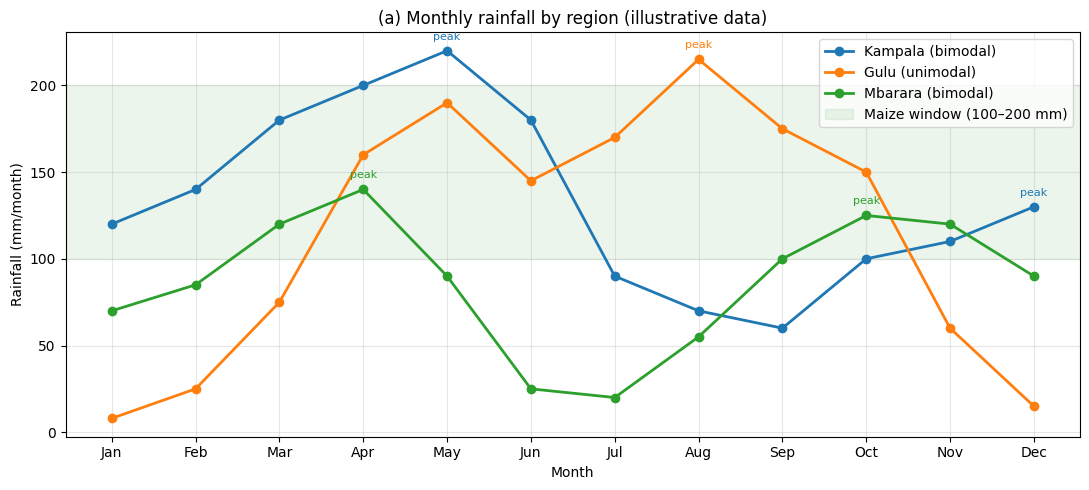

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
for i, r in enumerate(regions):
    ax.plot(MONTHS, r.rainfall, "-o", lw=2, color=f"C{i}", label=f"{r.name} ({r.modality()})")
    for p in r.rainy_season_peaks():
        ax.annotate("peak", (p, r.rainfall[p]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8, color=f"C{i}")
ax.axhspan(100, 200, color="green", alpha=0.08, label="Maize window (100–200 mm)")
ax.set_xlabel("Month")
ax.set_ylabel("Rainfall (mm/month)")
ax.set_title("(a) Monthly rainfall by region (illustrative data)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

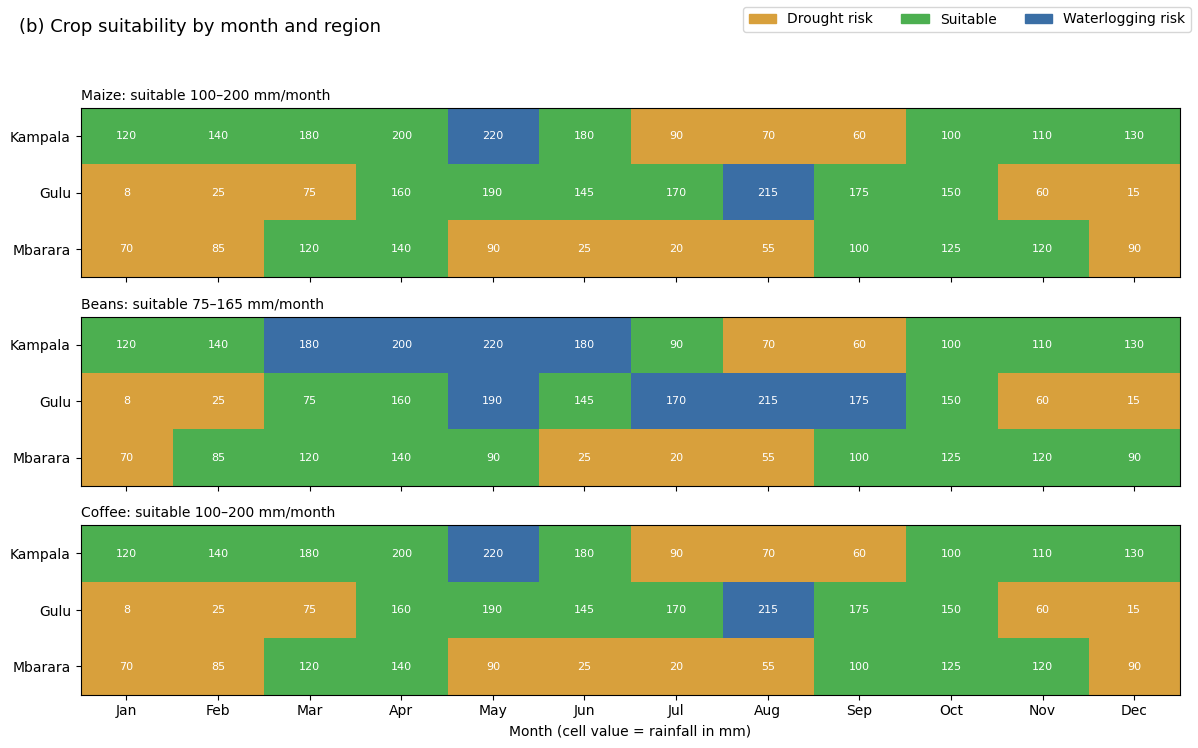

In [10]:
cmap = ListedColormap(["#d8a03c", "#4caf50", "#3a6ea5"])
fig, axes = plt.subplots(len(crops), 1, figsize=(12, 7.5), sharex=True)
for ax, crop in zip(axes, crops):
    codes = np.array([[crop.code(mm) for mm in r.rainfall] for r in regions])
    ax.imshow(codes, cmap=cmap, vmin=-1, vmax=1, aspect="auto")
    for i, r in enumerate(regions):
        for j, mm in enumerate(r.rainfall):
            ax.text(j, i, f"{mm:.0f}", ha="center", va="center", fontsize=8, color="white")
    ax.set_yticks(range(len(regions)), [r.name for r in regions])
    ax.set_title(f"{crop.name.capitalize()}: suitable {crop.min_mm:.0f}–{crop.max_mm:.0f} mm/month", fontsize=10, loc="left")
axes[-1].set_xticks(range(12), MONTHS)
axes[-1].set_xlabel("Month (cell value = rainfall in mm)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cmap.colors]
fig.legend(handles, ["Drought risk", "Suitable", "Waterlogging risk"], loc="upper right", ncol=3)
fig.suptitle("(b) Crop suitability by month and region", x=0.02, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

## 7. Advisory note: farmers in Mbarara

> **To farmers in Mbarara: what to plant and when**
>
> Mbarara has **two rainy seasons**: March–May and September–November. A dry spell runs from June to August.
>
> **Beans are your safest crop.** The rainfall suits beans in 8 of the 12 months, and a 3-month bean crop fits inside each season.
> * *Season 1:* plant when the March rains have properly started (the soil is moist to a hand's depth, usually mid-March). Harvest in June, before the dry spell.
> * *Season 2:* plant in early September and harvest by early December.
>
> **Maize: plant it in the second season.** Plant at the start of September so the crop flowers in the October–November peak. A 4–5-month maize crop planted in March would still be filling its grain in the June–July dry spell (only 20–25 mm a month). If you do plant maize in season 1, use an early-maturing variety and sow right at the onset.
>
> **Don't plant by the calendar alone.** In the 2014–2023 records, a month's rain often differed from its average by 40% or more. Wait for the rains to settle, keep some seed back in case you need to replant, and mulch to hold soil moisture through dry weeks.

*(Word count: 198, within the 200-word limit.)*

## Extension: real NASA POWER rainfall, 2014–2023

In [11]:
real = load_nasa_power_csv("data/nasa_power_monthly_rainfall.csv")
real_regions = [Region(f"{name} (NASA)", table.mean().to_numpy()) for name, table in real.items()]
for name, table in real.items():
    print(f"{name}: {table.shape[0]} years x {table.shape[1]} months, years {table.index.min()}-{table.index.max()}")
comparison = pd.DataFrame({
    r.name: {"annual mean (mm)": r.annual_total(), "CV": r.coefficient_of_variation(),
             "season peaks": ", ".join(MONTHS[p] for p in r.rainy_season_peaks()), "modality": r.modality()}
    for r in real_regions
}).T
comparison

Gulu: 10 years x 12 months, years 2014-2023
Kampala: 10 years x 12 months, years 2014-2023
Mbarara: 10 years x 12 months, years 2014-2023


,annual mean (mm),CV,season peaks,modality
Gulu (NASA),"1,415.759",0.546,Oct,unimodal
Kampala (NASA),"1,505.879",0.511,"Apr, Nov",bimodal
Mbarara (NASA),"1,313.749",0.416,"Apr, Oct",bimodal


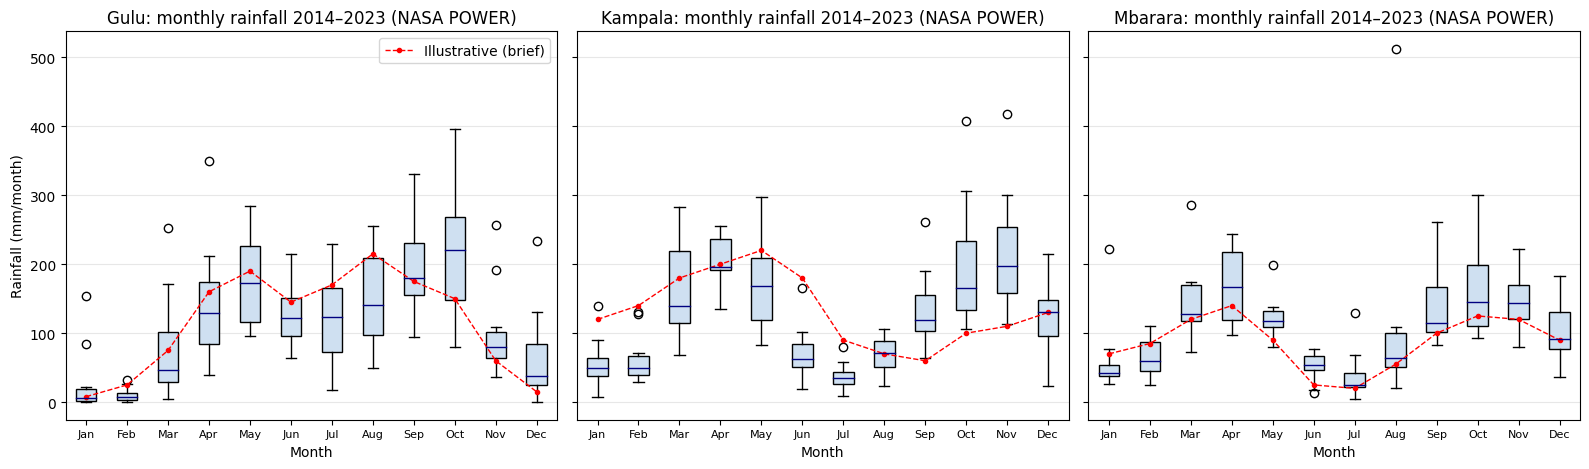

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, (name, table), ill in zip(axes, real.items(), [raw[n] for n in real]):
    ax.boxplot([table[m].to_numpy() for m in MONTHS], patch_artist=True,
               boxprops=dict(facecolor="#cfe0f1"), medianprops=dict(color="navy"))
    ax.set_xticks(range(1, 13), MONTHS)
    ax.plot(range(1, 13), ill, "r--o", ms=3, lw=1, label="Illustrative (brief)")
    ax.set_title(f"{name}: monthly rainfall 2014–2023 (NASA POWER)")
    ax.set_xlabel("Month")
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("Rainfall (mm/month)")
axes[0].legend()
fig.tight_layout()
plt.show()

In [13]:
variability = pd.DataFrame({name: (table.std(ddof=1) / table.mean()) for name, table in real.items()}).T
print("Year-to-year CV of each month's rainfall (NASA POWER 2014-2023):")
display(variability.round(2))
reliability = pd.DataFrame({
    name: {c.name: f"{(table.apply(lambda col: col.map(c.code)) == 0).to_numpy().mean():.0%}" for c in crops}
    for name, table in real.items()
}).T
print("Share of all month-years that fall in each crop's suitable window:")
reliability

Year-to-year CV of each month's rainfall (NASA POWER 2014-2023):


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Gulu,1.760,1.050,1.030,0.630,0.380,0.350,0.540,0.460,0.350,0.430,0.690,1.130
Kampala,0.640,0.590,0.460,0.180,0.400,0.560,0.520,0.380,0.420,0.490,0.430,0.430
Mbarara,0.930,0.460,0.420,0.340,0.270,0.410,0.920,1.290,0.450,0.400,0.310,0.460


Share of all month-years that fall in each crop's suitable window:


,maize,beans,coffee
Gulu,34%,36%,34%
Kampala,38%,37%,38%
Mbarara,39%,45%,39%


**What the real data add.**
* The real seasonal *shapes* agree with the illustrative data's modality: Kampala and Mbarara are bimodal, Gulu unimodal, and the same detection code confirms this. The details differ, though. Real Kampala is much drier in January–February (about 57–63 mm against the illustrative 120–140 mm), and its second season peaks in October–November, not December.
* **Year-to-year variability is large.** Most months have a between-year CV of about 0.35–0.7. The dry-season months are far less reliable (Gulu's January CV is 1.76, Mbarara's August 1.29). A planting calendar built on average rainfall hides the risk farmers actually face. Only 34–45% of all month-years fall inside each crop's suitable window, fewer than the illustrative climatology implies.
* Real Mbarara has a wetter second season (144–160 mm in September–November) than the illustrative data suggest, and a milder June–August dry spell. That supports the advice to put the longer-cycle crop in the second season. August is very erratic, though (CV 1.29), so September, not August, is the safe planting month.

## Findings & Limitations

**Findings.** The three regions have distinct rainfall regimes, and the analysis turns them into practical advice. Kampala and Mbarara are bimodal and Gulu is unimodal. The circular `find_peaks` method with a dry-spell merging rule reproduced this for both the illustrative and the real NASA data, so it can be trusted on new regions. Kampala's illustrative climate is the most forgiving: 8 months suit maize and coffee, because it never becomes very dry. Gulu offers one long April–October window suited to a single long-cycle crop. Mbarara suits beans across two short seasons. The similarity analysis shows why the choice of measure matters. Cosine similarity rated every pair as fairly alike (0.75–0.89) and gives a perfect 1.0 for Kampala against a region twice as wet, which has only half as many maize-suitable months. Pearson correlation (−0.17 to 0.21) shows that the *timing* of the seasons differs, and Euclidean distance captures the *amount*. For crop advice both timing and amount matter, so cosine similarity on its own is the least useful of the three. The real data add the most important caution: rainfall in a given month varies hugely between years (CV above 1 in dry months), and only 34–45% of month-years fall inside each crop's window.

**Limitations.** Monthly totals hide how rain is spread within a month, and a two-week dry spell inside a "good" month can still kill seedlings. The thresholds are generic FAO ranges divided by season length. They ignore soil water-holding capacity, temperature, evapotranspiration and growth stage (crops need more water at flowering than at sowing). NASA POWER is a satellite/reanalysis product on a coarse (~0.5°) grid, not a rain-gauge record, and ten years is short for climate statistics. Season detection depends on the 5 mm prominence and the mean-based dry threshold, both judgement calls.